# Análisis exploratorio de datos (EDA) · Segmentación de manzanas

## Objetivo

Antes de elegir filtros, espacios de color o modelos hay que **entender los datos**. Este notebook es la fase 0 del pipeline:
no transforma las imágenes que usarán los modelos, sino que las **mide**, para que cada decisión del preprocesado y de los
modelos esté justificada con números.

Preguntas que responde:

| # | Pregunta | Para qué sirve |
|---|---|---|
| 1 | ¿El dataset está completo y es coherente? | Poder confiar en los datos |
| 2 | ¿Qué variedades de manzana hay y en qué imágenes? | Estratificar el split y analizar por variedad |
| 3 | ¿Cómo repartimos train / validación / test? | Evaluación honesta |
| 4 | ¿Cuánta área ocupan las manzanas? | Elegir métricas adecuadas al desbalanceo |
| 5 | ¿Qué canal de color separa mejor manzana y fondo? ¿Sirve el gris estándar? | Espacio de color del preprocesado |
| 6 | ¿Qué "gris de manzana" (color → un canal) funciona mejor? | Configuraciones P5/P6 del preprocesado |
| 7 | ¿La textura separa la manzana donde el color falla? | Características de los modelos supervisados |
| 8 | ¿Qué tamaño y forma tienen las manzanas? | Morfología, filtro de área, Hough, watershed  |
| 9 | ¿Cómo es la iluminación? ¿Hay ruido? | Elegir CLAHE, gamma y filtros de ruido |
| 10 | ¿Las anotaciones son completas? | Interpretar bien los falsos positivos |

El conjunto de **test no se usa en ningún momento**. Todo se calcula con train, salvo la comparación de candidatos
a "gris de manzana", que se ajusta en train y se **mide en validación** (igual que se hará con Optuna).

Las funciones que también usarán las fases
siguientes están en `src/`: carga de datos, canales de color, curvas ROC/PR, medidas por manzana y ruido.

In [1]:
import csv
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# El notebook está en la carpeta experimentos/. Añadimos la carpeta del proyecto
# para poder importar config.py y el código de src/.
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from config import EDA_OUTPUT_DIR, IMAGE_SCALE, RANDOM_SEED, YELLOW_IMAGE_MAX_INDEX
from src.datos.loader import load_dataset, stratified_split
from src.metricas.curvas import curves_from_histograms, score_histograms
from src.metricas.objeto import component_stats, disc_reference
from src.metricas.pixel import pixel_metrics
from src.preprocesado.color import (
    CHANNEL_ORDER,
    FIXED_CANDIDATES,
    LEARNED_CANDIDATES,
    HistogramBackprojection,
    channel_images,
)
from src.preprocesado.ruido import estimate_gaussian_noise, impulse_noise_fraction

CARPETA_RESULTADOS = Path(EDA_OUTPUT_DIR)
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 80
COLORES = {"amarilla": "#d4a017", "roja": "#c0392b", "todas": "#4a4a4a"}
GRUPOS = ["todas", "amarilla", "roja"]


def redimensionar(muestra):
    # La imagen se reduce con INTER_AREA (promedia píxeles, no inventa colores)
    # y la máscara con INTER_NEAREST (así sigue siendo binaria).
    alto, ancho = muestra.image.shape[:2]
    nuevo_tamano = (int(ancho * IMAGE_SCALE), int(alto * IMAGE_SCALE))
    imagen = cv2.resize(muestra.image, nuevo_tamano, interpolation=cv2.INTER_AREA)
    mascara = cv2.resize(muestra.mask.astype(np.uint8), nuevo_tamano, interpolation=cv2.INTER_NEAREST)
    return imagen, mascara > 0


def guardar_csv(filas, nombre):
    with open(CARPETA_RESULTADOS / nombre, "w", newline="", encoding="utf-8") as fichero:
        escritor = csv.DictWriter(fichero, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)


def guardar_figura(figura, nombre):
    figura.savefig(CARPETA_RESULTADOS / nombre, dpi=130, bbox_inches="tight")
    plt.show()


print("Los resultados se guardan en:", CARPETA_RESULTADOS)

Los resultados se guardan en: C:\Users\aleja\Desktop\4ANYO\1CUATRI\visionComp\proyecto\SegmentacionManzanas\resultados\eda


## 1. Carga y verificación del dataset

`load_dataset()` empareja cada imagen con su máscara por nombre, convierte BGR → RGB (OpenCV lee en BGR), binariza la
máscara (`> 127`) y comprueba que todas las imágenes tienen la misma resolución. Si falta una máscara o un tamaño no
cuadra, lanza un error en lugar de seguir con datos corruptos.

In [2]:
muestras = load_dataset()

muestras_por_id = {}
for muestra in muestras:
    muestras_por_id[muestra.image_id] = muestra

tamanos_distintos = set()
todas_con_manzana = True
for muestra in muestras:
    tamanos_distintos.add(muestra.image.shape)
    if not muestra.mask.any():
        todas_con_manzana = False

imagen_reducida, _ = redimensionar(muestras[0])

print("Número de imágenes:", len(muestras))
print("Tamaños distintos (alto, ancho, canales):", tamanos_distintos)
print("¿Todas las máscaras tienen alguna manzana?", todas_con_manzana)
print("Tamaño de trabajo a escala", IMAGE_SCALE, ":", imagen_reducida.shape)

Número de imágenes: 100
Tamaños distintos (alto, ancho, canales): {(1280, 720, 3)}
¿Todas las máscaras tienen alguna manzana? True
Tamaño de trabajo a escala 0.5 : (640, 360, 3)


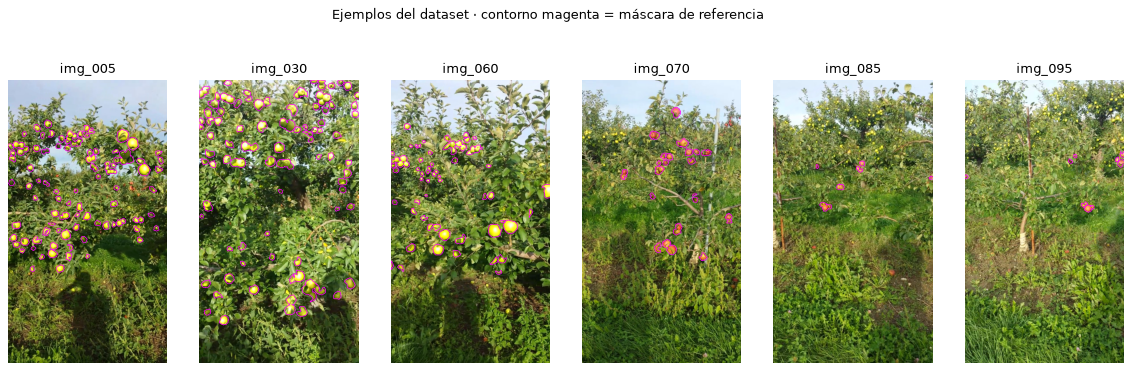

In [3]:
ids_ejemplo = ["img_005", "img_030", "img_060", "img_070", "img_085", "img_095"]

figura, ejes = plt.subplots(1, len(ids_ejemplo), figsize=(18, 5.5))
for i in range(len(ids_ejemplo)):
    muestra = muestras_por_id[ids_ejemplo[i]]
    imagen, mascara = redimensionar(muestra)
    ejes[i].imshow(imagen)
    ejes[i].contour(mascara, levels=[0.5], colors="#ff00ff", linewidths=0.6)
    ejes[i].set_title(muestra.image_id)
    ejes[i].axis("off")
figura.suptitle("Ejemplos del dataset · contorno magenta = máscara de referencia")
guardar_figura(figura, "ejemplos_dataset.png")

Observamos 100 imágenes verticales de 720×1280 con su máscara, donde todas tienen al menos una manzana anotada.
Hay dos escenas distintas: árboles grandes cargados de **manzanas amarillo-verdosas** y árboles jóvenes con pocas
**manzanas rojas**. En ambas, el fondo (hojas, césped) es verde y las manzanas son pequeñas respecto a la imagen.
Trabajaremos a escala 0,5 (360×640) para que el ajuste de hiperparámetros sea rápido, mientras que las estadísticas de forma se miden a
resolución original para no perder las manzanas pequeñas.

## 2. Variedades: ¿qué imágenes son amarillas y cuáles rojas?

Hay que saberlo por dos motivos: **estratificar** el split (que train, validación y test tengan las dos variedades en la
misma proporción) y **analizar por separado**, porque un canal que funciona con una variedad puede fallar con la otra.

En vez de fiarnos de una estimación visual, lo medimos: para cada imagen, la fracción de píxeles de manzana claramente
rojos, usando el canal a\* de Lab (eje verde → rojo). En OpenCV, a\* va de 0 a 255 con el valor neutro en 128,
así que consideramos rojo un píxel con a\* > 128 + 15.

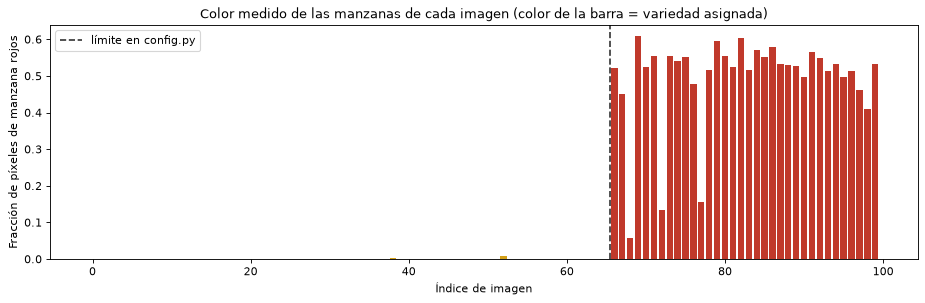

Imágenes amarillas: 66 · imágenes rojas: 34
Amarillas con más de un 5 % de píxeles rojos: []
Rojas con menos de un 30 % de píxeles rojos: ['img_068', 'img_072', 'img_077']


In [4]:
fraccion_roja = []
colores_barras = []
for muestra in muestras:
    lab = cv2.cvtColor(muestra.image, cv2.COLOR_RGB2LAB)
    a_estrella = lab[:, :, 1][muestra.mask].astype(int) - 128
    fraccion_roja.append(np.mean(a_estrella > 15))
    colores_barras.append(COLORES[muestra.variety])

figura, eje = plt.subplots(figsize=(14, 3.8))
eje.bar(range(len(muestras)), fraccion_roja, color=colores_barras)
eje.axvline(YELLOW_IMAGE_MAX_INDEX + 0.5, color="#333", linestyle="--", label="límite en config.py")
eje.set_xlabel("Índice de imagen")
eje.set_ylabel("Fracción de píxeles de manzana rojos")
eje.set_title("Color medido de las manzanas de cada imagen (color de la barra = variedad asignada)")
eje.legend()
guardar_figura(figura, "variedades.png")

amarillas_raras = []
rojas_raras = []
numero_amarillas = 0
numero_rojas = 0
for i in range(len(muestras)):
    if muestras[i].variety == "amarilla":
        numero_amarillas += 1
        if fraccion_roja[i] > 0.05:
            amarillas_raras.append(muestras[i].image_id)
    else:
        numero_rojas += 1
        if fraccion_roja[i] < 0.3:
            rojas_raras.append(muestras[i].image_id)

print("Imágenes amarillas:", numero_amarillas, "· imágenes rojas:", numero_rojas)
print("Amarillas con más de un 5 % de píxeles rojos:", amarillas_raras)
print("Rojas con menos de un 30 % de píxeles rojos:", rojas_raras)

Las imágenes `img_000`–`img_065` son del huerto amarillo (fracción roja ≈ 0) y `img_066`–`img_099` de la
escena de manzanas rojas: **66 amarillas y 34 rojas**. 

Algunas imágenes de la escena roja (`img_068`, `img_072`, `img_077`) tienen poca fracción roja, por lo que quizá son árboles jóvenes con
manzanas bicolores o todavía verdosas. Siguen siendo la misma escena y variedad, y así se etiquetan.

## 3. Partición train / validación / test (60/20/20)

- **Por imagen**, nunca por píxel: los píxeles de una misma imagen están muy correlacionados, y mezclarlos entre train y
  test inflaría las métricas.
- **Estratificada por variedad** y con **semilla fija** (reproducible).
- Los sobrantes del redondeo se reparten por el método del **mayor resto**, para que el total sea exactamente 60/20/20.
- **Train** se usa para aprender (histogramas, modelos supervisados); **validación** para comparar y ajustar
  hiperparámetros (Optuna); **test** solo una vez, al final de cada experimento.

In [5]:
particion = stratified_split(muestras)

train = []
for image_id in particion.train:
    train.append(muestras_por_id[image_id])

validacion = []
for image_id in particion.validation:
    validacion.append(muestras_por_id[image_id])

test = []
for image_id in particion.test:
    test.append(muestras_por_id[image_id])

filas_split = []
print(f"{'Split':<12}{'Imágenes':>9}{'Amarillas':>11}{'Rojas':>7}{'% manzana':>11}{'Mín. imagen':>13}{'Máx. imagen':>13}")
for nombre, conjunto in [("train", train), ("validación", validacion), ("test", test)]:
    amarillas = 0
    pixeles_manzana = 0
    pixeles_totales = 0
    prevalencias = []
    for muestra in conjunto:
        if muestra.variety == "amarilla":
            amarillas += 1
        pixeles_manzana += muestra.mask.sum()
        pixeles_totales += muestra.mask.size
        prevalencias.append(muestra.mask.mean())
    prevalencia = pixeles_manzana / pixeles_totales
    fila = {
        "split": nombre,
        "imagenes": len(conjunto),
        "amarillas": amarillas,
        "rojas": len(conjunto) - amarillas,
        "prevalencia": prevalencia,
        "prevalencia_min": min(prevalencias),
        "prevalencia_max": max(prevalencias),
    }
    filas_split.append(fila)
    print(f"{nombre:<12}{len(conjunto):>9}{amarillas:>11}{len(conjunto) - amarillas:>7}"
          f"{100 * prevalencia:>10.2f}%{100 * min(prevalencias):>12.2f}%{100 * max(prevalencias):>12.2f}%")

guardar_csv(filas_split, "split_resumen.csv")

Split        Imágenes  Amarillas  Rojas  % manzana  Mín. imagen  Máx. imagen
train              60         40     20      4.39%        0.24%       10.06%
validación         20         13      7      4.37%        0.22%        9.21%
test               20         13      7      3.75%        0.25%        8.99%


## 4. Desbalanceo: ¿cuánta área ocupan las manzanas?

La tabla anterior ya lo adelanta: solo un ~4 % de los píxeles son manzana. Veamos la distribución por imagen y qué
consecuencia tiene sobre las métricas con un "modelo" trivial que predice **todo fondo**.

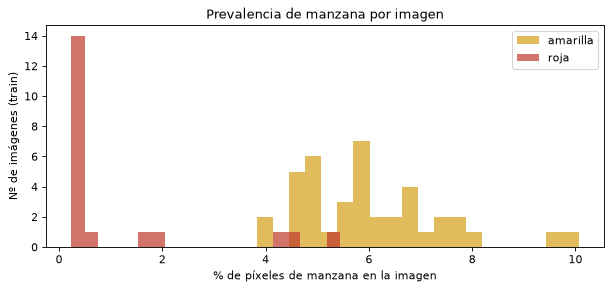

Predecir TODO fondo en train:
  accuracy   0.956
  precision  0.000
  recall     0.000
  f1         0.000
  iou        0.000
  mcc        0.000


In [6]:
figura, eje = plt.subplots(figsize=(9, 3.6))
for variedad in ["amarilla", "roja"]:
    porcentajes = []
    for muestra in train:
        if muestra.variety == variedad:
            porcentajes.append(100 * muestra.mask.mean())
    eje.hist(porcentajes, bins=20, alpha=0.7, color=COLORES[variedad], label=variedad)
eje.set_xlabel("% de píxeles de manzana en la imagen")
eje.set_ylabel("Nº de imágenes (train)")
eje.set_title("Prevalencia de manzana por imagen")
eje.legend()
guardar_figura(figura, "prevalencia.png")

# "Modelo" trivial: dice que todos los píxeles de train son fondo.
mascaras_train = []
for muestra in train:
    mascaras_train.append(muestra.mask.ravel())
verdad = np.concatenate(mascaras_train)
prediccion_todo_fondo = np.zeros_like(verdad)
metricas = pixel_metrics(verdad, prediccion_todo_fondo)

print("Predecir TODO fondo en train:")
for nombre in ["accuracy", "precision", "recall", "f1", "iou", "mcc"]:
    print(f"  {nombre:<10} {metricas[nombre]:.3f}")

En conclusión, un modelo que no detecta ninguna manzana obtiene una *accuracy* de ~0,96 y, sin embargo, F1, IoU y MCC
valen 0. Por tanto:

- La **accuracy no sirve** como métrica principal. Se usarán **F1/Dice, IoU, MCC** y, para los mapas de puntuación,
  el **área bajo la curva precisión-recall (PR-AUC / AP)**, más informativa que el ROC-AUC con este desbalanceo.
- Los modelos supervisados se entrenarán con un **muestreo balanceado** de píxeles; si no, aprenderían a decir "fondo".
- Las rojas tienen muy poca manzana por imagen (árboles jóvenes), por lo que serán las más difíciles.

## 5. ¿Qué canal de color separa la manzana del fondo?

Medimos cada canal de los espacios de color (RGB, HSV, Lab, YCrCb y gris) como si fuera un clasificador por sí solo. Se añade un canal más: la
**distancia circular del matiz al rojo**. En OpenCV, H va de 0 a 179 y el rojo está en *los dos extremos* (≈0 y ≈179), así
que un umbral sobre H en bruto parte las manzanas rojas en dos; `min(H, 180 − H)` pone el rojo en 0.

Dos medidas de separabilidad:

- **ROC-AUC**: probabilidad de que un píxel de manzana elegido al azar tenga un valor mayor que uno de fondo
  (0,5 = azar, 1 = separación perfecta). Se toma el mejor sentido (mayor o menor), porque en algunos canales la manzana
  es más *baja* (p. ej. Cb).
- **Varianza interclase / intraclase**: el mismo criterio que maximiza Otsu. Si es alto, un umbral global separará bien.

Para que las imágenes con muchas manzanas no dominen, se toman como máximo 5000 píxeles de cada clase por imagen (train, escala 0,5). Se calcula para todas las imágenes juntas y **por variedad**.

In [7]:
MAXIMO_POR_CLASE = 5000


def muestrear_pixeles(conjunto):
    # Devuelve, para cada canal, los valores de píxeles de manzana y de fondo
    # (como máximo MAXIMO_POR_CLASE de cada clase por imagen).
    generador = np.random.default_rng(RANDOM_SEED)
    valores_manzana = {}
    valores_fondo = {}
    for canal in CHANNEL_ORDER:
        valores_manzana[canal] = []
        valores_fondo[canal] = []

    for muestra in conjunto:
        imagen, mascara = redimensionar(muestra)
        indices_manzana = np.flatnonzero(mascara)
        indices_fondo = np.flatnonzero(~mascara)
        if len(indices_manzana) > MAXIMO_POR_CLASE:
            indices_manzana = generador.choice(indices_manzana, MAXIMO_POR_CLASE, replace=False)
        if len(indices_fondo) > MAXIMO_POR_CLASE:
            indices_fondo = generador.choice(indices_fondo, MAXIMO_POR_CLASE, replace=False)

        canales = channel_images(imagen)
        for canal in CHANNEL_ORDER:
            valores = canales[canal].ravel()
            valores_manzana[canal].append(valores[indices_manzana])
            valores_fondo[canal].append(valores[indices_fondo])

    for canal in CHANNEL_ORDER:
        valores_manzana[canal] = np.concatenate(valores_manzana[canal])
        valores_fondo[canal] = np.concatenate(valores_fondo[canal])
    return valores_manzana, valores_fondo


separabilidad = {}   # clave: (grupo, espacio, canal)
histogramas = {}     # clave: (grupo, espacio, canal) -> (histograma manzana, histograma fondo)
filas_separabilidad = []

for grupo in GRUPOS:
    conjunto = []
    for muestra in train:
        if grupo == "todas" or muestra.variety == grupo:
            conjunto.append(muestra)
    valores_manzana, valores_fondo = muestrear_pixeles(conjunto)

    for canal in CHANNEL_ORDER:
        manzana = valores_manzana[canal]
        fondo = valores_fondo[canal]

        # AUC a partir de los histogramas (implementación propia, src/metricas/curvas.py)
        histograma_manzana = np.bincount(manzana, minlength=256)
        histograma_fondo = np.bincount(fondo, minlength=256)
        auc = curves_from_histograms(histograma_manzana, histograma_fondo)["roc_auc"]
        if auc >= 0.5:
            sentido = "mayor"
        else:
            sentido = "menor"
            auc = 1 - auc

        # Criterio de Otsu: varianza entre clases / varianza dentro de las clases
        peso_manzana = len(manzana) / (len(manzana) + len(fondo))
        peso_fondo = 1 - peso_manzana
        varianza_entre = peso_manzana * peso_fondo * (manzana.mean() - fondo.mean()) ** 2
        varianza_dentro = peso_manzana * manzana.var() + peso_fondo * fondo.var()

        clave = (grupo, canal[0], canal[1])
        histogramas[clave] = (histograma_manzana, histograma_fondo)
        separabilidad[clave] = {"auc": auc, "sentido": sentido, "ratio": varianza_entre / varianza_dentro}
        filas_separabilidad.append({
            "variedad": grupo, "espacio": canal[0], "canal": canal[1], "imagenes": len(conjunto),
            "media_manzana": manzana.mean(), "media_fondo": fondo.mean(),
            "auc": auc, "sentido": sentido, "inter_intra": varianza_entre / varianza_dentro,
        })

guardar_csv(filas_separabilidad, "separabilidad_canales.csv")

canales_clave = [
    ("Gris", "Y", "Gris estándar Y"),
    ("Lab", "a*", "a* (Lab)"),
    ("Lab", "b*", "b* (Lab)"),
    ("YCrCb", "Cr", "Cr (YCrCb)"),
    ("YCrCb", "Cb", "Cb (YCrCb)"),
    ("HSV", "H", "H en bruto"),
    ("Matiz", "dist_rojo", "Dist. circular al rojo"),
    ("HSV", "S", "S (HSV)"),
    ("RGB", "R", "R (RGB)"),
]
print(f"{'Canal':<24}{'AUC todas':>11}{'AUC amarillas':>15}{'AUC rojas':>11}{'Inter/intra':>13}")
for espacio, canal, nombre in canales_clave:
    linea = f"{nombre:<24}"
    for grupo in GRUPOS:
        resultado = separabilidad[(grupo, espacio, canal)]
        marca = " "
        if resultado["sentido"] == "menor":
            marca = "↓"
        if grupo == "amarilla":
            linea += f"{resultado['auc']:>14.3f}{marca}"
        else:
            linea += f"{resultado['auc']:>10.3f}{marca}"
    linea += f"{separabilidad[('todas', espacio, canal)]['ratio']:>13.3f}"
    print(linea)
print("\n↓ = en ese canal la manzana tiene valores MENORES que el fondo")

Canal                     AUC todas  AUC amarillas  AUC rojas  Inter/intra
Gris estándar Y              0.734          0.757      0.646         0.194
a* (Lab)                     0.532↓         0.639↓     0.929         0.003
b* (Lab)                     0.873          0.895      0.765         0.662
Cr (YCrCb)                   0.882          0.876      0.968         0.548
Cb (YCrCb)                   0.880↓         0.900↓     0.780↓        0.715
H en bruto                   0.824↓         0.820↓     0.945↓        0.174
Dist. circular al rojo       0.825↓         0.820↓     0.950↓        0.261
S (HSV)                      0.681          0.683      0.649         0.108
R (RGB)                      0.788          0.792      0.799         0.331

↓ = en ese canal la manzana tiene valores MENORES que el fondo


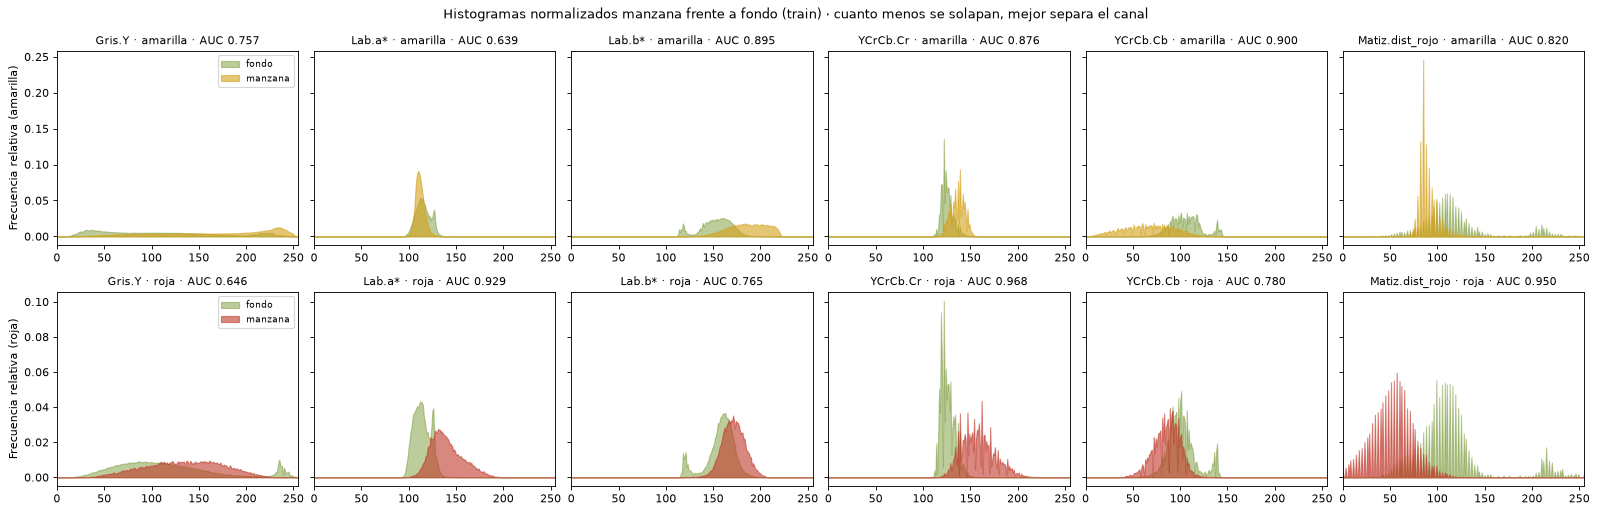

In [8]:
canales_a_dibujar = [("Gris", "Y"), ("Lab", "a*"), ("Lab", "b*"), ("YCrCb", "Cr"), ("YCrCb", "Cb"), ("Matiz", "dist_rojo")]

figura, ejes = plt.subplots(2, len(canales_a_dibujar), figsize=(20, 6.5), sharey="row")
for fila, variedad in enumerate(["amarilla", "roja"]):
    for columna, (espacio, canal) in enumerate(canales_a_dibujar):
        histograma_manzana, histograma_fondo = histogramas[(variedad, espacio, canal)]
        eje = ejes[fila, columna]
        eje.fill_between(range(256), histograma_fondo / histograma_fondo.sum(), color="#6b8e23", alpha=0.45, label="fondo")
        eje.fill_between(range(256), histograma_manzana / histograma_manzana.sum(), color=COLORES[variedad], alpha=0.6, label="manzana")
        auc = separabilidad[(variedad, espacio, canal)]["auc"]
        eje.set_title(f"{espacio}.{canal} · {variedad} · AUC {auc:.3f}", fontsize=10)
        eje.set_xlim(0, 255)
    ejes[fila, 0].set_ylabel(f"Frecuencia relativa ({variedad})")
    ejes[fila, 0].legend(fontsize=8)
figura.suptitle("Histogramas normalizados manzana frente a fondo (train) · cuanto menos se solapan, mejor separa el canal")
figura.tight_layout()
guardar_figura(figura, "histogramas_canales.png")

**Interpretación.**

- El **gris estándar separa mal**, sobre todo en las rojas (AUC ≈ 0,65): una manzana roja y una hoja pueden tener el
  mismo brillo. Se confirma que hay que convertir el color de otra forma.
- **Cada variedad tiene su canal**: las amarillas se separan mejor por el eje azul–amarillo (**Cb** ↓, **b\***, ≈ 0,90) y
  las rojas por el eje rojo (**Cr** ≈ 0,97, **a\*** ≈ 0,93, matiz ≈ 0,95).
- **Mezclar variedades engaña**: a\* parece inútil con todas juntas (≈ 0,53) y es casi perfecto en las rojas. Sin el
  análisis por variedad lo habríamos descartado.
- El matiz en bruto y la distancia circular dan un AUC parecido porque el AUC elige el mejor sentido, pero solo la
  distancia circular permite **un único umbral** para todo el rojo; es la versión que usará el preprocesado.
- **Ningún canal funciona bien para las dos variedades a la vez**: motiva combinar canales (siguiente sección).

## 6. "Gris de manzana": convertir el color en un solo canal donde la manzana destaque

Un **gris de manzana** es una imagen de un solo canal (0–255) calculada a partir del color, en la que la manzana sale
**clara** y el fondo **oscuro**. No usamos el brillo, sino una transformación del color. Todos los candidatos salen de los temas vistos en teoría:

| Candidato | Definición | Tema |
|---|---|---|
| Gris estándar Y | 0,299R + 0,587G + 0,114B (referencia) | 2 |
| Cr, b\*, 255 − Cb | un canal de YCrCb o Lab | 2 |
| max(a\*, b\*) | cada variedad destaca en uno de los dos ejes de Lab | 2, 3 |
| (Cr + 255 − Cb) / 2 | rojo **y** amarillo lejos del azul/verde a la vez | 2, 3 |
| Matiz cercano al rojo | 255 − distancia circular del matiz al rojo | 2 |
| **Retroproyección del histograma** | histograma 2D de colores de manzana y de fondo en train, normalizados (tema 6: "interpretar probabilidades"); cada píxel recibe P(manzana \| color) con `cv2.calcBackProject` | 6 |

Las retroproyecciones **aprenden** en train, todos los candidatos se **miden en validación** con **todos** los píxeles (sin muestrear), y se reportan:

- **ROC-AUC**: no depende del desbalanceo.
- **AP (Average Precision, área PR)**: parte de la prevalencia (~4 %) y penaliza confundir mucho fondo con manzana. Es la que más se parece a lo que pasará al umbralizar.

In [9]:
# 1) Entrenar las retroproyecciones con las imágenes de train
imagenes_train = []
mascaras_train = []
for muestra in train:
    imagen, mascara = redimensionar(muestra)
    imagenes_train.append(imagen)
    mascaras_train.append(mascara)

candidatos = {}
for nombre, funcion in FIXED_CANDIDATES.items():
    candidatos[nombre] = funcion
aprendidos = []
for nombre, parametros in LEARNED_CANDIDATES.items():
    retroproyeccion = HistogramBackprojection(parametros["color_space"], parametros["channels"])
    retroproyeccion.fit(imagenes_train, mascaras_train)
    candidatos[nombre] = retroproyeccion
    aprendidos.append(nombre)

# 2) Acumular, en validación, el histograma de puntuaciones de manzana y de fondo
acumulado = {}
for nombre in candidatos:
    for grupo in GRUPOS:
        acumulado[(nombre, grupo)] = [np.zeros(256, dtype=np.int64), np.zeros(256, dtype=np.int64)]

for muestra in validacion:
    imagen, mascara = redimensionar(muestra)
    for nombre, funcion in candidatos.items():
        puntuacion = funcion(imagen)
        histograma_manzana, histograma_fondo = score_histograms(puntuacion, mascara)
        for grupo in ["todas", muestra.variety]:
            acumulado[(nombre, grupo)][0] += histograma_manzana
            acumulado[(nombre, grupo)][1] += histograma_fondo

# 3) Calcular ROC-AUC y AP de cada candidato
resultados = {}
filas_candidatos = []
for nombre in candidatos:
    for grupo in GRUPOS:
        curvas = curves_from_histograms(acumulado[(nombre, grupo)][0], acumulado[(nombre, grupo)][1])
        resultados[(nombre, grupo)] = curvas
        filas_candidatos.append({
            "candidato": nombre, "aprendido": nombre in aprendidos, "variedad": grupo,
            "prevalencia": curvas["prevalence"], "roc_auc": curvas["roc_auc"], "ap": curvas["average_precision"],
            "mejor_f1_orientativo": curvas["best_f1"], "umbral_mejor_f1": curvas["best_f1_threshold"],
        })
guardar_csv(filas_candidatos, "candidatos_gris_manzana.csv")

# 4) Ordenar de mejor a peor AP (todas las variedades)
pares = []
for nombre in candidatos:
    pares.append((resultados[(nombre, "todas")]["average_precision"], nombre))
pares.sort(reverse=True)
orden = []
for ap, nombre in pares:
    orden.append(nombre)

print(f"{'Candidato':<32}{'Aprendido':>10}{'AUC todas':>11}{'AP todas':>10}{'AP amarillas':>14}{'AP rojas':>10}")
for nombre in orden:
    if nombre in aprendidos:
        aprendido = "sí"
    else:
        aprendido = "no"
    print(f"{nombre:<32}{aprendido:>10}"
          f"{resultados[(nombre, 'todas')]['roc_auc']:>11.3f}"
          f"{resultados[(nombre, 'todas')]['average_precision']:>10.3f}"
          f"{resultados[(nombre, 'amarilla')]['average_precision']:>14.3f}"
          f"{resultados[(nombre, 'roja')]['average_precision']:>10.3f}")
print("\nPrevalencia en validación (AP de un clasificador al azar):",
      round(resultados[(orden[0], "todas")]["prevalence"], 3))

Candidato                        Aprendido  AUC todas  AP todas  AP amarillas  AP rojas
(Cr + 255 − Cb) / 2                     no      0.895     0.610         0.648     0.536
Retroproyección Cr–Cb (YCrCb)           sí      0.903     0.603         0.641     0.471
Retroproyección a*–b* (Lab)             sí      0.899     0.584         0.624     0.458
255 − Cb (YCrCb)                        no      0.875     0.558         0.629     0.028
max(a*, b*)                             no      0.869     0.545         0.613     0.033
b* (Lab)                                no      0.867     0.543         0.613     0.027
Cr (YCrCb)                              no      0.856     0.291         0.345     0.706
Retroproyección H–S (HSV)               sí      0.869     0.274         0.327     0.239
Matiz cercano al rojo                   no      0.809     0.128         0.165     0.435
Gris estándar Y                         no      0.741     0.126         0.194     0.010

Prevalencia en validación (AP d

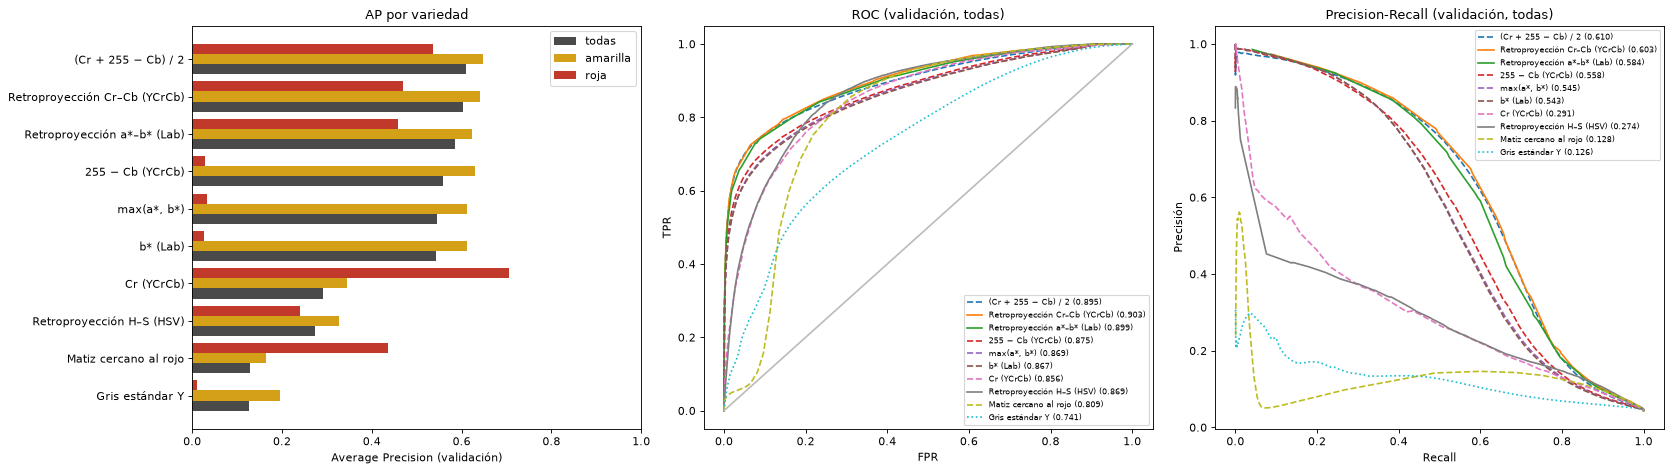

In [10]:
figura, ejes = plt.subplots(1, 3, figsize=(21, 6))

# Barras de AP por variedad
posiciones = np.arange(len(orden))[::-1]
desplazamientos = {"todas": -0.27, "amarilla": 0.0, "roja": 0.27}
for grupo in GRUPOS:
    valores = []
    for nombre in orden:
        valores.append(resultados[(nombre, grupo)]["average_precision"])
    ejes[0].barh(posiciones + desplazamientos[grupo], valores, height=0.27, color=COLORES[grupo], label=grupo)
ejes[0].set_yticks(posiciones)
ejes[0].set_yticklabels(orden)
ejes[0].set_xlim(0, 1)
ejes[0].set_xlabel("Average Precision (validación)")
ejes[0].set_title("AP por variedad")
ejes[0].legend()

# Curvas ROC y Precision-Recall
for nombre in orden:
    curvas = resultados[(nombre, "todas")]
    if nombre == "Gris estándar Y":
        estilo = ":"
    elif nombre in aprendidos:
        estilo = "-"
    else:
        estilo = "--"
    ejes[1].plot(curvas["fpr"], curvas["tpr"], estilo, label=f"{nombre} ({curvas['roc_auc']:.3f})")
    ejes[2].plot(curvas["recall"], curvas["precision"], estilo, label=f"{nombre} ({curvas['average_precision']:.3f})")
ejes[1].plot([0, 1], [0, 1], color="#bbb")
ejes[1].set_xlabel("FPR")
ejes[1].set_ylabel("TPR")
ejes[1].set_title("ROC (validación, todas)")
ejes[1].legend(fontsize=7)
ejes[2].set_xlabel("Recall")
ejes[2].set_ylabel("Precisión")
ejes[2].set_title("Precision-Recall (validación, todas)")
ejes[2].legend(fontsize=7)

figura.tight_layout()
guardar_figura(figura, "candidatos_gris_manzana.png")

**Interpretación.**

- El mejor candidato es **(Cr + 255 − Cb) / 2**, una transformación **fija** de canales de YCrCb: AP ≈ 0,61 frente a
  ≈ 0,13 del gris estándar (**casi 5 veces más**). Esto es, rojo y amarillo quedan claros a la vez porque los dos están lejos del azul–verde del follaje.
- La **retroproyección Cr–Cb** queda prácticamente empatada (≈ 0,60) y la a\*–b\* cerca. En las rojas rinden menos porque
  train tiene muchas más manzanas amarillas y el histograma aprende sobre todo ese color. Se puede mejorar dando el
  mismo peso a cada variedad al construir el histograma.
- En las rojas gana **Cr** solo (AP ≈ 0,71), y los canales del eje amarillo (b\*, 255 − Cb, max(a\*, b\*)) se hunden a
  AP ≈ 0,03 aunque su AUC sea razonable: en esas imágenes resaltan manzanas amarillas de las filas del fondo, que no
  están anotadas, y hierbas iluminadas (sección 10).
- AUC y AP ordenan distinto a los candidatos: con este desbalanceo, el AP es el criterio para elegir.

**Decisión para el preprocesado:** (Cr + 255 − Cb)/2 como "gris de manzana" principal (P6), con la retroproyección como
alternativa aprendida; Cr como canal específico del rojo. El mejor F1 por umbral del CSV se elige sobre la propia
validación, así que es optimista y solo sirve para comparar.

Veamos qué aspecto tienen en dos imágenes de **validación** (una de cada variedad):

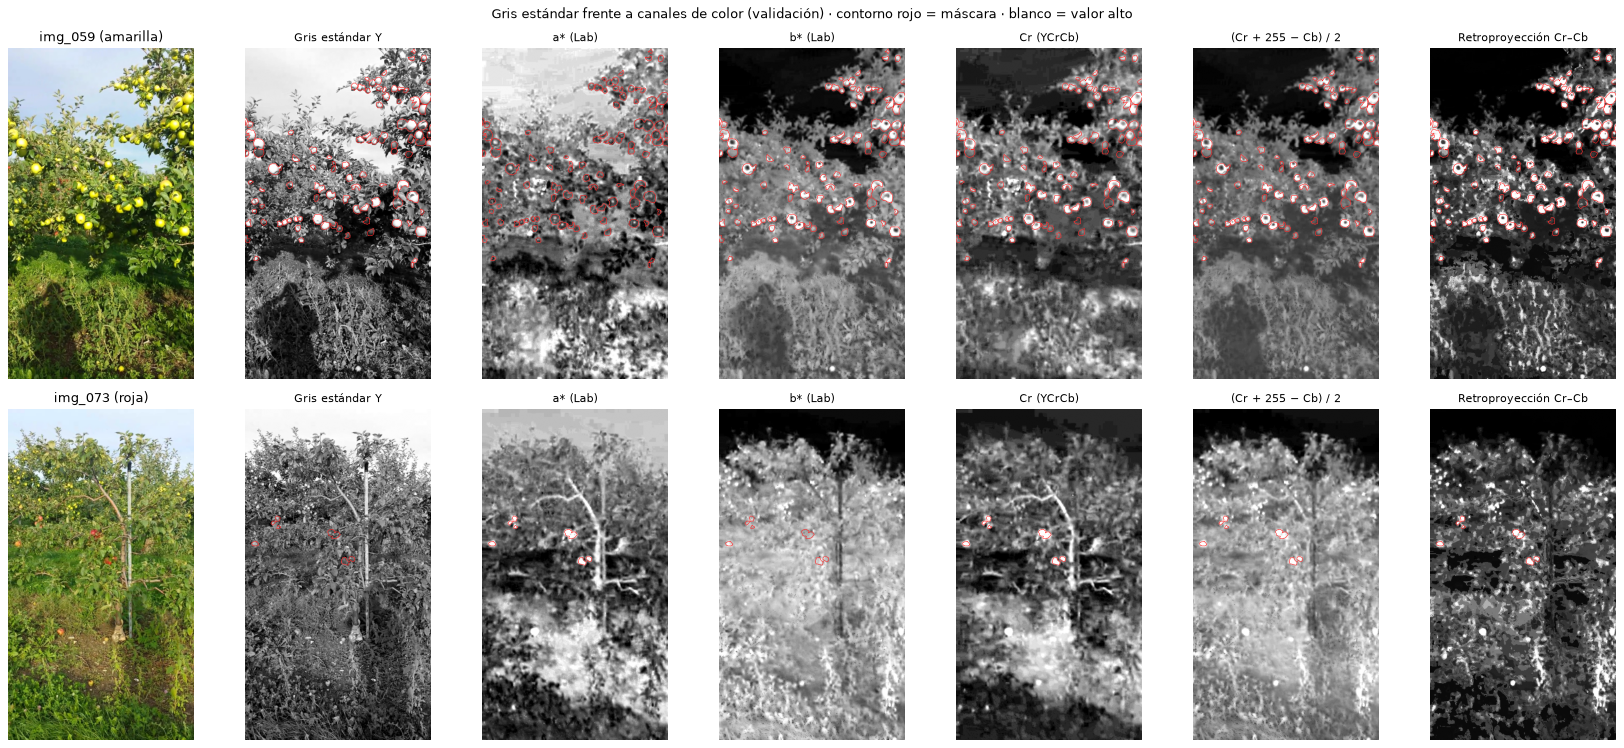

In [11]:
def estirar_contraste(canal):
    # Lleva los percentiles 1 y 99 a 0 y 1 para que se vea bien el contraste.
    minimo, maximo = np.percentile(canal, [1, 99])
    return np.clip((canal.astype(float) - minimo) / (maximo - minimo), 0, 1)


def canal_a_estrella(imagen):
    return cv2.cvtColor(imagen, cv2.COLOR_RGB2LAB)[:, :, 1]


def elegir_ejemplo(variedad):
    # Imagen de validación con la prevalencia mediana: ni la más fácil ni la más difícil.
    pares = []
    for muestra in validacion:
        if muestra.variety == variedad:
            pares.append((muestra.mask.mean(), muestra.image_id))
    pares.sort()
    mediana = pares[len(pares) // 2]
    return muestras_por_id[mediana[1]]


paneles = [
    ("Gris estándar Y", FIXED_CANDIDATES["Gris estándar Y"]),
    ("a* (Lab)", canal_a_estrella),
    ("b* (Lab)", FIXED_CANDIDATES["b* (Lab)"]),
    ("Cr (YCrCb)", FIXED_CANDIDATES["Cr (YCrCb)"]),
    ("(Cr + 255 − Cb) / 2", FIXED_CANDIDATES["(Cr + 255 − Cb) / 2"]),
    ("Retroproyección Cr–Cb", candidatos["Retroproyección Cr–Cb (YCrCb)"]),
]

figura, ejes = plt.subplots(2, len(paneles) + 1, figsize=(21, 9.5))
for fila, variedad in enumerate(["amarilla", "roja"]):
    muestra = elegir_ejemplo(variedad)
    imagen, mascara = redimensionar(muestra)
    ejes[fila, 0].imshow(imagen)
    ejes[fila, 0].set_title(f"{muestra.image_id} ({variedad})")
    for columna, (titulo, funcion) in enumerate(paneles, start=1):
        ejes[fila, columna].imshow(estirar_contraste(funcion(imagen)), cmap="gray")
        ejes[fila, columna].contour(mascara, levels=[0.5], colors="#ff2d2d", linewidths=0.5)
        ejes[fila, columna].set_title(titulo, fontsize=10)
    for columna in range(len(paneles) + 1):
        ejes[fila, columna].axis("off")
figura.suptitle("Gris estándar frente a canales de color (validación) · contorno rojo = máscara · blanco = valor alto")
figura.tight_layout()
guardar_figura(figura, "canales_ejemplo.png")

En el gris estándar las manzanas rojas desaparecen entre el follaje; en Cr y en (Cr + 255 − Cb)/2 destacan en las dos
variedades. También se aprecia que el césped iluminado y algunos troncos quedan claros: un umbral solo no bastará y habrá
que filtrar por **forma y tamaño** (sección 8) o añadir información de **textura** (sección 7).

## 7. Textura: ¿ayuda donde el color falla?

El color separa bien, pero no del todo: hierbas iluminadas, tallos o tierra pueden tener el mismo color que una manzana
(sección 10). Los modelos supervisados (KNN, SVM, Random Forest) usarán también **características de textura**, y hay que
comprobar que aportan algo. La hipótesis es que la piel de la manzana es **lisa** y las hojas y la hierba son **rugosas**.

Características, calculadas sobre el gris estándar (la textura es una propiedad del brillo, no del
color):

| Característica | Qué mide |
|---|---|
| Desviación típica local | Variación de brillo en una ventana (con filtros de media) |
| Magnitud del gradiente de Sobel (media local) | Cantidad de bordes |
| \|Laplaciana de la Gaussiana\| (media local) | Bordes y puntos a una escala σ |
| Contraste LBP (media local) | Medida de contraste del LBP: media de vecinos ≥ centro − media de vecinos < centro |
| **Retroproyección LBP** | Qué códigos LBP son típicos de manzana: histogramas de códigos de manzana y de fondo en train, normalizados (igual que la retroproyección de color), promediados en una ventana |

Las funciones están en `src/caracteristicas/textura.py`, porque las usarán los modelos.

La pregunta clave no es solo si la textura separa la manzana de *todo* el fondo, sino si la separa del **fondo que el
color confunde**: píxeles de fondo con (Cr + 255 − Cb)/2 por encima del umbral de mejor F1 de la sección 6. Si ahí
funciona, aporta información **complementaria** al color. Se toman como máximo 3000 píxeles de cada grupo por imagen de
train y se mide el AUC (mejor sentido) de cada característica.

In [12]:
from src.caracteristicas.textura import (
    RetroproyeccionLBP,
    contraste_lbp,
    desviacion_local,
    magnitud_log,
    magnitud_sobel,
    media_local,
)

MAXIMO_TEXTURA = 3000
VENTANA = 7          # ventana de las medidas locales (≈ diámetro de una manzana a escala 0,5)
VENTANA_LBP = 9
umbral_color = resultados[(orden[0], "todas")]["best_f1_threshold"]
color_de_manzana = FIXED_CANDIDATES["(Cr + 255 − Cb) / 2"]

# 1) Aprender qué códigos LBP son típicos de manzana (solo con train)
grises_train = []
grises_suavizados_train = []
for imagen in imagenes_train:
    gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)
    grises_train.append(gris)
    grises_suavizados_train.append(cv2.GaussianBlur(gris, (0, 0), 1))
retro_lbp = RetroproyeccionLBP(VENTANA_LBP)
retro_lbp.fit(grises_train, mascaras_train)
retro_lbp_suavizado = RetroproyeccionLBP(VENTANA_LBP)
retro_lbp_suavizado.fit(grises_suavizados_train, mascaras_train)


def caracteristicas_textura(gris):
    caracteristicas = {}
    caracteristicas["Desviación local"] = desviacion_local(gris, VENTANA)
    caracteristicas["Sobel (media local)"] = media_local(magnitud_sobel(gris), VENTANA)
    caracteristicas["|LoG| σ=2 (media local)"] = media_local(magnitud_log(gris, 2), VENTANA)
    caracteristicas["Contraste LBP (media local)"] = media_local(contraste_lbp(gris), VENTANA)
    caracteristicas["Retroproyección LBP"] = retro_lbp.transform(gris)
    caracteristicas["Retroproyección LBP (gris suavizado σ=1)"] = retro_lbp_suavizado.transform(
        cv2.GaussianBlur(gris, (0, 0), 1))
    return caracteristicas


def elegir_indices(mascara, generador):
    indices = np.flatnonzero(mascara)
    if len(indices) > MAXIMO_TEXTURA:
        indices = generador.choice(indices, MAXIMO_TEXTURA, replace=False)
    return indices


def auc_mejor_sentido(valores_manzana, valores_fondo):
    # Se cuantizan los valores a 256 niveles para usar curves_from_histograms.
    todos = np.concatenate([valores_manzana, valores_fondo])
    minimo, maximo = np.percentile(todos, [0.5, 99.5])
    niveles_manzana = np.clip((valores_manzana - minimo) / (maximo - minimo) * 255, 0, 255).astype(int)
    niveles_fondo = np.clip((valores_fondo - minimo) / (maximo - minimo) * 255, 0, 255).astype(int)
    auc = curves_from_histograms(np.bincount(niveles_manzana, minlength=256),
                                 np.bincount(niveles_fondo, minlength=256))["roc_auc"]
    if auc >= 0.5:
        return auc, "mayor"
    return 1 - auc, "menor"


# 2) Muestrear píxeles de manzana, de todo el fondo y del fondo con color de manzana
generador = np.random.default_rng(RANDOM_SEED)
textura = {}   # clave: (variedad, característica, grupo de píxeles) -> lista de arrays
for indice in range(len(train)):
    imagen = imagenes_train[indice]
    mascara = mascaras_train[indice]
    variedad = train[indice].variety
    fondo_confuso = (color_de_manzana(imagen) >= umbral_color) & ~mascara

    indices_manzana = elegir_indices(mascara, generador)
    indices_fondo = elegir_indices(~mascara, generador)
    indices_confuso = elegir_indices(fondo_confuso, generador)

    for nombre, mapa in caracteristicas_textura(grises_train[indice]).items():
        valores = mapa.ravel()
        for grupo, indices in [("manzana", indices_manzana), ("fondo", indices_fondo), ("confuso", indices_confuso)]:
            clave = (variedad, nombre, grupo)
            if clave not in textura:
                textura[clave] = []
            textura[clave].append(valores[indices])


def juntar(variedades, nombre, grupo):
    partes = []
    for variedad in variedades:
        partes = partes + textura[(variedad, nombre, grupo)]
    return np.concatenate(partes)


# 3) AUC de cada característica
nombres_textura = list(caracteristicas_textura(grises_train[0]).keys())
filas_textura = []
print(f"{'Característica':<42}{'vs todo el fondo':>17}{'vs fondo confuso':>18}{'amarillas':>11}{'rojas':>9}")
for nombre in nombres_textura:
    linea = f"{nombre:<42}"
    comparaciones = [
        (["amarilla", "roja"], "fondo", "todas", 17),
        (["amarilla", "roja"], "confuso", "todas", 18),
        (["amarilla"], "confuso", "amarilla", 11),
        (["roja"], "confuso", "roja", 9),
    ]
    for variedades, grupo_fondo, variedad, ancho in comparaciones:
        auc, sentido = auc_mejor_sentido(juntar(variedades, nombre, "manzana"), juntar(variedades, nombre, grupo_fondo))
        marca = " "
        if sentido == "menor":
            marca = "↓"
        linea += f"{auc:>{ancho - 1}.3f}{marca}"
        filas_textura.append({"caracteristica": nombre, "variedad": variedad, "frente_a": grupo_fondo,
                              "auc": auc, "sentido": sentido})
    print(linea)
guardar_csv(filas_textura, "textura_separabilidad.csv")

numero_confusos = len(juntar(["amarilla", "roja"], nombres_textura[0], "confuso"))
print(f"\n↓ = la manzana tiene valores MENORES (más lisa) · píxeles de fondo confuso muestreados: {numero_confusos}")

Característica                             vs todo el fondo  vs fondo confuso  amarillas    rojas
Desviación local                                     0.683             0.547↓     0.545↓   0.679↓
Sobel (media local)                                  0.640             0.601↓     0.592↓   0.713↓
|LoG| σ=2 (media local)                              0.787             0.544      0.576    0.668↓
Contraste LBP (media local)                          0.597             0.635↓     0.632↓   0.726↓
Retroproyección LBP                                  0.901             0.792      0.795    0.719 
Retroproyección LBP (gris suavizado σ=1)             0.858             0.712      0.731    0.594 

↓ = la manzana tiene valores MENORES (más lisa) · píxeles de fondo confuso muestreados: 137952


 Una manzana mide unos 12 px de diámetro a escala 0,5. Medimos el AUC frente al fondo
que el color confunde con distintas ventanas (la tabla de probabilidades del LBP no cambia; solo la ventana en la que se
promedia):

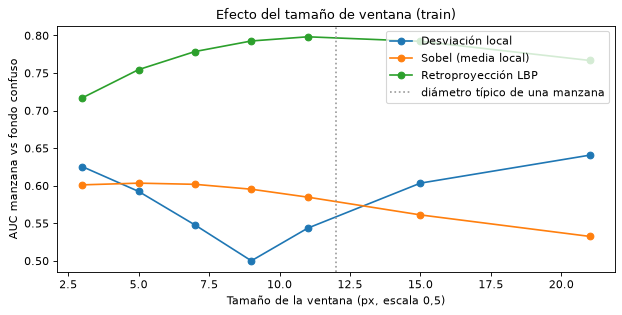

Desviación local        w=3: 0.625  w=5: 0.592  w=7: 0.548  w=9: 0.500  w=11: 0.543  w=15: 0.603  w=21: 0.641
Sobel (media local)     w=3: 0.601  w=5: 0.603  w=7: 0.602  w=9: 0.595  w=11: 0.585  w=15: 0.561  w=21: 0.533
Retroproyección LBP     w=3: 0.717  w=5: 0.755  w=7: 0.779  w=9: 0.793  w=11: 0.798  w=15: 0.792  w=21: 0.767


In [13]:
ventanas = [3, 5, 7, 9, 11, 15, 21]
curvas_ventana = {"Desviación local": [], "Sobel (media local)": [], "Retroproyección LBP": []}

for ventana in ventanas:
    generador = np.random.default_rng(RANDOM_SEED)
    retro_ventana = RetroproyeccionLBP(ventana)
    retro_ventana.probabilidad = retro_lbp.probabilidad   # mismos histogramas, otra ventana
    valores = {}
    for nombre in curvas_ventana:
        valores[(nombre, "manzana")] = []
        valores[(nombre, "confuso")] = []
    for indice in range(len(train)):
        imagen = imagenes_train[indice]
        mascara = mascaras_train[indice]
        gris = grises_train[indice]
        fondo_confuso = (color_de_manzana(imagen) >= umbral_color) & ~mascara
        indices_manzana = elegir_indices(mascara, generador)
        indices_confuso = elegir_indices(fondo_confuso, generador)
        mapas = {
            "Desviación local": desviacion_local(gris, ventana),
            "Sobel (media local)": media_local(magnitud_sobel(gris), ventana),
            "Retroproyección LBP": retro_ventana.transform(gris),
        }
        for nombre, mapa in mapas.items():
            valores[(nombre, "manzana")].append(mapa.ravel()[indices_manzana])
            valores[(nombre, "confuso")].append(mapa.ravel()[indices_confuso])
    for nombre in curvas_ventana:
        auc, _ = auc_mejor_sentido(np.concatenate(valores[(nombre, "manzana")]),
                                   np.concatenate(valores[(nombre, "confuso")]))
        curvas_ventana[nombre].append(auc)

figura, eje = plt.subplots(figsize=(9, 4))
for nombre, aucs in curvas_ventana.items():
    eje.plot(ventanas, aucs, "o-", label=nombre)
eje.axvline(12, color="#999", linestyle=":", label="diámetro típico de una manzana")
eje.set_xlabel("Tamaño de la ventana (px, escala 0,5)")
eje.set_ylabel("AUC manzana vs fondo confuso")
eje.set_title("Efecto del tamaño de ventana (train)")
eje.legend()
guardar_figura(figura, "textura_ventanas.png")

for nombre, aucs in curvas_ventana.items():
    texto = ""
    for ventana, auc in zip(ventanas, aucs):
        texto += f"  w={ventana}: {auc:.3f}"
    print(f"{nombre:<22}{texto}")

Por último, la comprobación importante se hace en **validación** (la retroproyección LBP aprendió en train): si
exigimos conservar el 90 % de los píxeles de manzana, ¿qué parte del fondo con color de manzana se elimina con la
textura? Y ¿está correlacionada la textura con el color? (si lo estuviera, no aportaría nada nuevo).

Validación · retroproyección LBP (ventana 9):
  AUC manzana vs fondo con color de manzana: 0.827
  Conservando el 90 % de la manzana se elimina el 49.8 % de ese fondo
  Correlación entre textura y color: 0.29


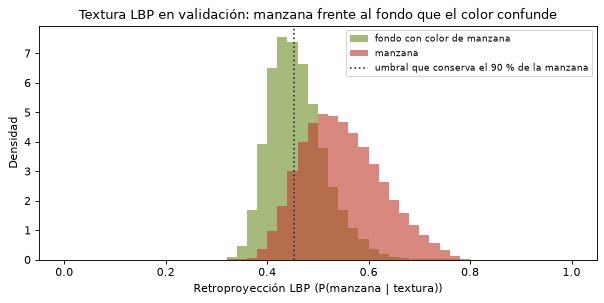

In [14]:
valores_manzana = []
valores_confuso = []
color_manzana = []
color_confuso = []
for muestra in validacion:
    imagen, mascara = redimensionar(muestra)
    gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)
    color = color_de_manzana(imagen)
    fondo_confuso = (color >= umbral_color) & ~mascara
    mapa_lbp = retro_lbp.transform(gris)
    valores_manzana.append(mapa_lbp[mascara])
    valores_confuso.append(mapa_lbp[fondo_confuso])
    color_manzana.append(color[mascara])
    color_confuso.append(color[fondo_confuso])
valores_manzana = np.concatenate(valores_manzana)
valores_confuso = np.concatenate(valores_confuso)
color_manzana = np.concatenate(color_manzana)
color_confuso = np.concatenate(color_confuso)

auc_validacion, _ = auc_mejor_sentido(valores_manzana, valores_confuso)
umbral_textura = np.percentile(valores_manzana, 10)        # conserva el 90 % de la manzana
eliminado = np.mean(valores_confuso < umbral_textura)
correlacion = np.corrcoef(np.concatenate([valores_manzana, valores_confuso]),
                          np.concatenate([color_manzana, color_confuso]))[0, 1]

print(f"Validación · retroproyección LBP (ventana {VENTANA_LBP}):")
print(f"  AUC manzana vs fondo con color de manzana: {auc_validacion:.3f}")
print(f"  Conservando el 90 % de la manzana se elimina el {100 * eliminado:.1f} % de ese fondo")
print(f"  Correlación entre textura y color: {correlacion:.2f}")

figura, eje = plt.subplots(figsize=(9, 3.8))
eje.hist(valores_confuso, bins=50, range=(0, 1), density=True, alpha=0.6, color="#6b8e23",
         label="fondo con color de manzana")
eje.hist(valores_manzana, bins=50, range=(0, 1), density=True, alpha=0.6, color="#c0392b", label="manzana")
eje.axvline(umbral_textura, color="#333", linestyle=":", label="umbral que conserva el 90 % de la manzana")
eje.set_xlabel("Retroproyección LBP (P(manzana | textura))")
eje.set_ylabel("Densidad")
eje.set_title("Textura LBP en validación: manzana frente al fondo que el color confunde")
eje.legend(fontsize=8)
guardar_figura(figura, "textura_lbp_validacion.png")

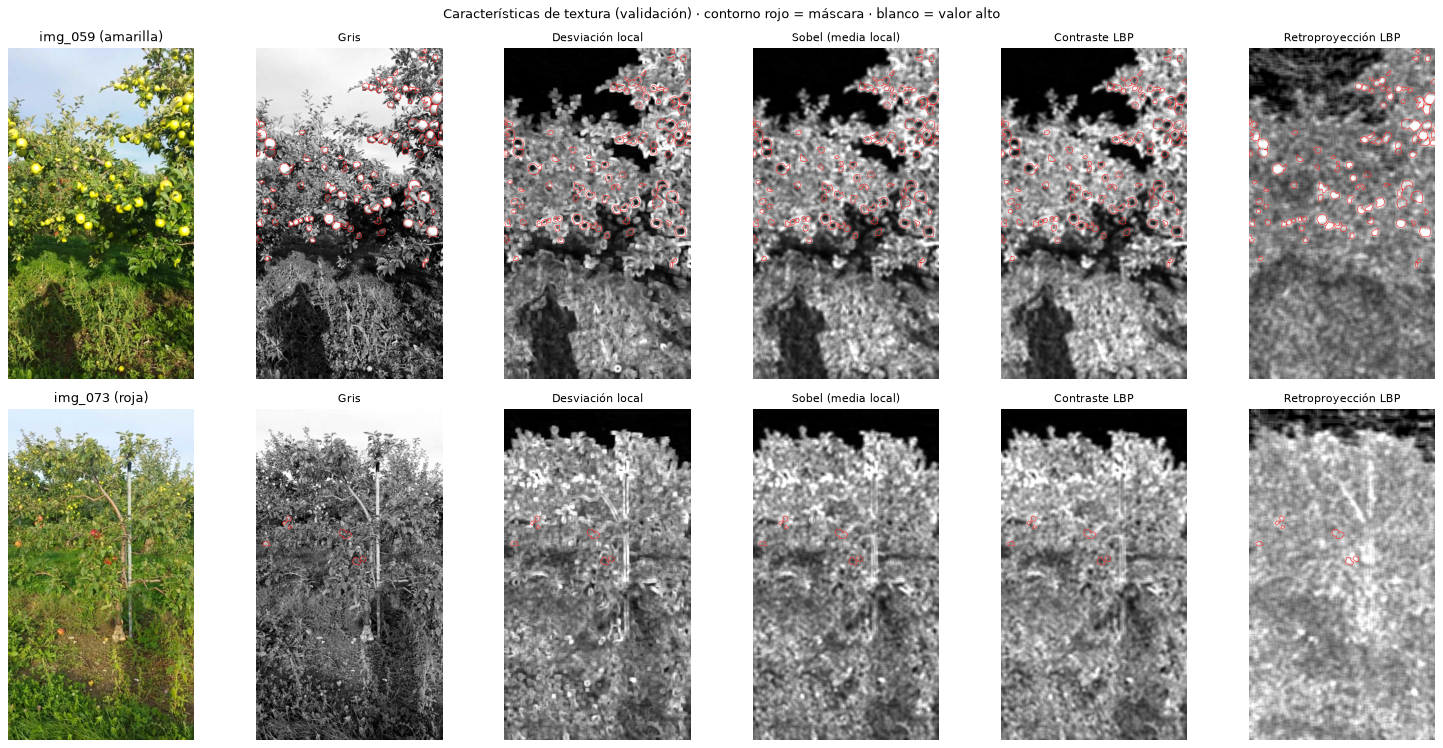

In [15]:
paneles_textura = [
    ("Gris", None),
    ("Desviación local", "Desviación local"),
    ("Sobel (media local)", "Sobel (media local)"),
    ("Contraste LBP", "Contraste LBP (media local)"),
    ("Retroproyección LBP", "Retroproyección LBP"),
]
figura, ejes = plt.subplots(2, len(paneles_textura) + 1, figsize=(19, 9.5))
for fila, variedad in enumerate(["amarilla", "roja"]):
    muestra = elegir_ejemplo(variedad)
    imagen, mascara = redimensionar(muestra)
    gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)
    mapas = caracteristicas_textura(gris)
    ejes[fila, 0].imshow(imagen)
    ejes[fila, 0].set_title(f"{muestra.image_id} ({variedad})")
    for columna, (titulo, nombre) in enumerate(paneles_textura, start=1):
        if nombre is None:
            mapa = gris
        else:
            mapa = mapas[nombre]
        ejes[fila, columna].imshow(estirar_contraste(mapa), cmap="gray")
        ejes[fila, columna].contour(mascara, levels=[0.5], colors="#ff2d2d", linewidths=0.5)
        ejes[fila, columna].set_title(titulo, fontsize=10)
    for columna in range(len(paneles_textura) + 1):
        ejes[fila, columna].axis("off")
figura.suptitle("Características de textura (validación) · contorno rojo = máscara · blanco = valor alto")
figura.tight_layout()
guardar_figura(figura, "textura_ejemplo.png")

**Interpretación y decisiones.**

- **Las medidas simples de "rugosidad" separan poco** (desviación local, Sobel, |LoG|, contraste LBP: AUC ≈ 0,55–0,75).
  Frente al fondo que el color confunde, la manzana sí es más **lisa** (↓), sobre todo en las rojas (Sobel ≈ 0,7), pero
  no basta por sí sola.
- **Cuidado con la ventana**: una manzana mide unos 12 px a escala 0,5, así que una ventana grande centrada en ella
  abarca su **borde** con las hojas y mide el contorno, no la piel. Se ve en la figura de ejemplo: en la desviación local
  y en Sobel cada manzana aparece como un **centro oscuro (piel lisa) rodeado de un anillo brillante (su borde)**. Y en la
  curva de ventanas: la desviación local separa porque la manzana es más lisa con w = 3, no separa nada con w = 9
  (AUC 0,50) y con ventanas grandes vuelve a separar, pero al revés (la manzana "parece" rugosa por su borde). Para
  describir la piel, las ventanas de rugosidad deben ser **pequeñas** (3–5 px).
- **Lo que funciona es la distribución de códigos LBP** (retroproyección): AUC ≈ 0,90 frente a todo el fondo y ≈ 0,8
  frente al fondo con color de manzana, en train y en validación. En validación, **conservando el 90 % de la manzana
  elimina alrededor de la mitad de ese fondo**, y su correlación con el color es baja (≈ 0,3): es información **nueva**,
  complementaria al color. El LBP describe la *forma* local del brillo (piel curva y lisa frente a hojas y tallos con
  bordes en todas direcciones), no solo cuánto varía. Su mejor ventana está entre 9 y 15 px (AUC ≈ 0,79–0,80), y
  funciona mejor en las amarillas (≈ 0,80) que en las rojas (≈ 0,72), donde también resalta objetos lisos como el tutor
  del árbol.
- **Suavizar antes del LBP empeora** (la versión con σ = 1 pierde AUC): aunque el tema 4 advierte de que el LBP es
  sensible al ruido, aquí el ruido es bajo (sección 9) y el suavizado borra el detalle que distingue la textura.

**Decisión para los modelos supervisados (M5–M7):** vector de características = **color** (canales y gris de manzana
de las secciones 5–6) + **retroproyección o histograma local de LBP** en una ventana de 9–11 px + desviación local y
Sobel con ventanas pequeñas (3–5 px) como apoyo. Los tamaños de ventana serán hiperparámetros para Optuna.

## 8. Tamaño y forma de las manzanas (componentes conexas)

Cada **componente conexa** (8-vecindad) de la máscara es una manzana anotada, o varias que se tocan. A resolución
original medimos:

- **Radio equivalente** r = √(área / π) → filtro de área mínima, tamaño del elemento estructurante y rango de radios para
  la transformada de Hough de círculos.
- **Circularidad** 4πA/P² (1 = círculo) → filtro de forma.
- **Solidez** A / A<sub>envolvente convexa</sub> → baja si hay varias manzanas fusionadas → justifica watershed.

Antes, una comprobación: en contornos **pixelados** el perímetro se sobreestima (escalones), así que un círculo perfecto
no da 1. Por eso normalizamos cada medida respecto a la de un **disco digital** del mismo radio.

In [16]:
for radio in [4, 7, 12, 24, 50]:
    circularidad, solidez = disc_reference(radio)
    print(f"Disco digital perfecto de radio {radio:>2} px → circularidad {circularidad:.3f} · solidez {solidez:.3f}")

Disco digital perfecto de radio  4 px → circularidad 0.766 · solidez 0.905
Disco digital perfecto de radio  7 px → circularidad 0.833 · solidez 0.942
Disco digital perfecto de radio 12 px → circularidad 0.859 · solidez 0.962
Disco digital perfecto de radio 24 px → circularidad 0.882 · solidez 0.980
Disco digital perfecto de radio 50 px → circularidad 0.891 · solidez 0.989


In [17]:
manzanas = []           # una fila por manzana anotada
manzanas_por_imagen = []
for muestra in train:
    medidas = component_stats(muestra.mask)
    manzanas_por_imagen.append({"image_id": muestra.image_id, "variedad": muestra.variety, "manzanas": len(medidas)})
    for medida in medidas:
        fila = {"image_id": muestra.image_id, "variedad": muestra.variety}
        fila.update(medida)
        manzanas.append(fila)
guardar_csv(manzanas, "objetos_componentes.csv")
guardar_csv(manzanas_por_imagen, "objetos_por_imagen.csv")

SOLIDEZ_BAJA = 0.85
print(f"{'Variedad':<10}{'Manzanas':>9}{'Por imagen (mín-med-máx)':>27}{'Radio p5/p50/p95':>20}"
      f"{'Circ. norm.':>13}{'Solidez norm.':>15}{'Solidez < 0.85':>16}{'(área)':>9}")
for grupo in GRUPOS:
    radios = []
    areas = []
    circularidades = []
    solideces = []
    for manzana in manzanas:
        if grupo == "todas" or manzana["variedad"] == grupo:
            radios.append(manzana["radio_equivalente"])
            areas.append(manzana["area"])
            circularidades.append(manzana["circularidad_norm"])
            solideces.append(manzana["solidez_norm"])
    radios = np.array(radios)
    areas = np.array(areas)
    solideces = np.array(solideces)

    cuentas = []
    for fila in manzanas_por_imagen:
        if grupo == "todas" or fila["variedad"] == grupo:
            cuentas.append(fila["manzanas"])

    p5, p50, p95 = np.percentile(radios, [5, 50, 95])
    baja = solideces < SOLIDEZ_BAJA
    print(f"{grupo:<10}{len(radios):>9}{min(cuentas):>15} - {np.median(cuentas):.0f} - {max(cuentas):<5}"
          f"{p5:>9.1f} /{p50:>5.1f} /{p95:>5.1f}"
          f"{np.nanmedian(circularidades):>13.2f}{np.nanmedian(solideces):>15.2f}"
          f"{100 * baja.mean():>15.1f}%{100 * areas[baja].sum() / areas.sum():>8.1f}%")

# Valores orientativos para el pipeline, a la escala de trabajo
todos_los_radios = []
todas_las_areas = []
for manzana in manzanas:
    todos_los_radios.append(manzana["radio_equivalente"])
    todas_las_areas.append(manzana["area"])
radio_p5 = np.percentile(todos_los_radios, 5) * IMAGE_SCALE
radio_p99 = np.percentile(todos_los_radios, 99) * IMAGE_SCALE
area_minima = np.percentile(todas_las_areas, 1) * IMAGE_SCALE ** 2
tamano_apertura = int(radio_p5)
if tamano_apertura % 2 == 0:
    tamano_apertura -= 1
if tamano_apertura < 3:
    tamano_apertura = 3

print(f"\nA escala {IMAGE_SCALE}: área mínima ≈ {area_minima:.0f} px · radios de Hough ≈ {radio_p5:.1f}–{radio_p99:.1f} px"
      f" · apertura como máximo {tamano_apertura}×{tamano_apertura}")

Variedad   Manzanas   Por imagen (mín-med-máx)    Radio p5/p50/p95  Circ. norm.  Solidez norm.  Solidez < 0.85   (área)
todas          3551              4 - 75 - 108        6.9 / 12.4 / 23.7         0.83           0.98           16.6%    27.3%
amarilla       3173             46 - 82 - 108        6.9 / 12.5 / 24.1         0.83           0.98           16.9%    27.5%
roja            378              4 - 8 - 86         7.1 / 11.7 / 20.7         0.84           0.99           14.3%    25.5%

A escala 0.5: área mínima ≈ 23 px · radios de Hough ≈ 3.4–17.0 px · apertura como máximo 3×3


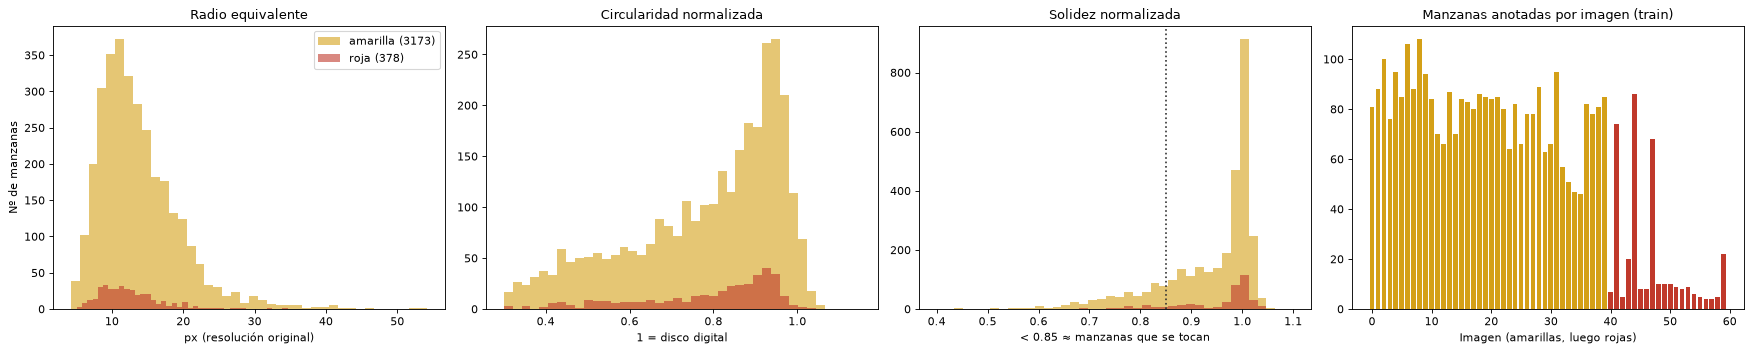

In [18]:
figura, ejes = plt.subplots(1, 4, figsize=(22, 4.5))
for variedad in ["amarilla", "roja"]:
    radios = []
    circularidades = []
    solideces = []
    for manzana in manzanas:
        if manzana["variedad"] == variedad:
            radios.append(manzana["radio_equivalente"])
            circularidades.append(manzana["circularidad_norm"])
            solideces.append(manzana["solidez_norm"])
    ejes[0].hist(radios, bins=40, alpha=0.6, color=COLORES[variedad], label=f"{variedad} ({len(radios)})")
    ejes[1].hist(circularidades, bins=40, range=(0.3, 1.15), alpha=0.6, color=COLORES[variedad])
    ejes[2].hist(solideces, bins=40, range=(0.4, 1.1), alpha=0.6, color=COLORES[variedad])
ejes[0].set_title("Radio equivalente")
ejes[0].set_xlabel("px (resolución original)")
ejes[0].set_ylabel("Nº de manzanas")
ejes[0].legend()
ejes[1].set_title("Circularidad normalizada")
ejes[1].set_xlabel("1 = disco digital")
ejes[2].axvline(SOLIDEZ_BAJA, color="#333", linestyle=":")
ejes[2].set_title("Solidez normalizada")
ejes[2].set_xlabel(f"< {SOLIDEZ_BAJA} ≈ manzanas que se tocan")

# Manzanas por imagen: primero las amarillas y luego las rojas
cuentas = []
colores_barras = []
for variedad in ["amarilla", "roja"]:
    for fila in manzanas_por_imagen:
        if fila["variedad"] == variedad:
            cuentas.append(fila["manzanas"])
            colores_barras.append(COLORES[variedad])
ejes[3].bar(range(len(cuentas)), cuentas, color=colores_barras)
ejes[3].set_title("Manzanas anotadas por imagen (train)")
ejes[3].set_xlabel("Imagen (amarillas, luego rojas)")

figura.tight_layout()
guardar_figura(figura, "objetos_estadisticas.png")

**Interpretación y decisiones.**

- Las manzanas son **pequeñas** (radio típico ≈ 12 px a resolución original, ≈ 6 px a escala 0,5) y la mayoría son casi
  tan redondas como un disco (circularidad y solidez normalizadas medianas ≈ 0,83 y ≈ 0,98) → tiene sentido un **filtro
  por circularidad** y probar la **transformada de Hough de círculos**.
- Alrededor de un **17 %** de las componentes (más de un **25 %** del área) tienen solidez baja: manzanas que se tocan u
  ocluidas por hojas → **watershed** con transformada de distancia para separarlas y contarlas.
- Los valores orientativos impresos arriba (área mínima, radios de Hough, tamaño máximo de la apertura) serán el punto de
  partida de los rangos de Optuna. Una apertura mayor que 3×3 a escala 0,5 borraría las manzanas pequeñas.
- Hay un **desbalanceo entre variedades** a nivel de objeto: en train hay unas 3200 manzanas amarillas frente a menos de
  400 rojas. Los modelos supervisados deben muestrear por variedad o las rojas quedarán infrarrepresentadas.

## 9. Iluminación, sobreexposición y ruido

Los filtros y ajustes de contraste solo se justifican si el problema existe. Por imagen de train medimos:

- **Brillo L\*** (Lab) de manzanas y fondo, y su dispersión → variaciones sol/sombra → **CLAHE**.
- **Manzana en sombra**: fracción de píxeles de manzana con L\* < 100 (sobre 255).
- **Brillo especular**: V ≥ 245 y S < 60 (zonas casi blancas) → huecos en la máscara → **mediana** y **cierre**.
- **Sobreexposición**: algún canal RGB ≥ 250 (el sensor recorta).
- **Ruido gaussiano**: σ estimado con el método de **Immerkær (1996)**, una convolución con una máscara laplaciana de
  suma cero, a resolución original.
- **Ruido impulsivo** (sal y pimienta): píxeles casi negros/blancos que difieren > 80 niveles de su mediana 3×3.

In [19]:
calidad = []
for muestra in train:
    imagen, mascara = redimensionar(muestra)
    brillo = cv2.cvtColor(imagen, cv2.COLOR_RGB2LAB)[:, :, 0].astype(float)
    hsv = cv2.cvtColor(imagen, cv2.COLOR_RGB2HSV)
    especular = (hsv[:, :, 2] >= 245) & (hsv[:, :, 1] < 60)
    sobreexpuesto = imagen.max(axis=2) >= 250
    gris_original = cv2.cvtColor(muestra.image, cv2.COLOR_RGB2GRAY)

    calidad.append({
        "image_id": muestra.image_id,
        "variedad": muestra.variety,
        "L_manzana": brillo[mascara].mean(),
        "L_std_manzana": brillo[mascara].std(),
        "L_fondo": brillo[~mascara].mean(),
        "sombra": np.mean(brillo[mascara] < 100),
        "especular": especular[mascara].mean(),
        "sobreexpuesta": sobreexpuesto[mascara].mean(),
        "sobreexpuesto_fondo": sobreexpuesto[~mascara].mean(),
        "sigma_ruido": estimate_gaussian_noise(gris_original),
        "impulsivo": impulse_noise_fraction(gris_original),
    })
guardar_csv(calidad, "iluminacion_por_imagen.csv")

print(f"{'Variedad':<10}{'L* manzana':>14}{'Desv. L*':>10}{'Sombra med/máx':>18}{'Especular med/máx':>20}"
      f"{'Sobreexp. manzana':>19}{'(fondo)':>9}{'σ ruido':>14}{'Impulsivo máx':>15}")
for grupo in GRUPOS:
    columnas = {}
    for clave in ["L_manzana", "L_std_manzana", "sombra", "especular", "sobreexpuesta",
                  "sobreexpuesto_fondo", "sigma_ruido", "impulsivo"]:
        columnas[clave] = []
    for fila in calidad:
        if grupo == "todas" or fila["variedad"] == grupo:
            for clave in columnas:
                columnas[clave].append(fila[clave])
    print(f"{grupo:<10}"
          f"{min(columnas['L_manzana']):>8.0f} - {max(columnas['L_manzana']):<3.0f}"
          f"{np.median(columnas['L_std_manzana']):>10.1f}"
          f"{100 * np.median(columnas['sombra']):>10.1f}% /{100 * max(columnas['sombra']):>5.1f}%"
          f"{100 * np.median(columnas['especular']):>11.1f}% /{100 * max(columnas['especular']):>5.1f}%"
          f"{100 * np.median(columnas['sobreexpuesta']):>18.1f}%"
          f"{100 * np.median(columnas['sobreexpuesto_fondo']):>8.1f}%"
          f"{min(columnas['sigma_ruido']):>8.2f} - {max(columnas['sigma_ruido']):<4.2f}"
          f"{100 * max(columnas['impulsivo']):>14.3f}%")

Variedad      L* manzana  Desv. L*    Sombra med/máx   Especular med/máx  Sobreexp. manzana  (fondo)       σ ruido  Impulsivo máx
todas          133 - 195      58.6      13.6% / 19.7%        0.5% / 10.3%              22.1%     1.9%    3.11 - 6.24         0.004%
amarilla       167 - 195      60.6      13.4% / 19.4%        1.1% / 10.3%              23.3%     0.4%    3.11 - 5.59         0.004%
roja           133 - 165      37.6      13.8% / 19.7%        0.0% /  0.1%              11.1%     7.4%    3.80 - 6.24         0.001%


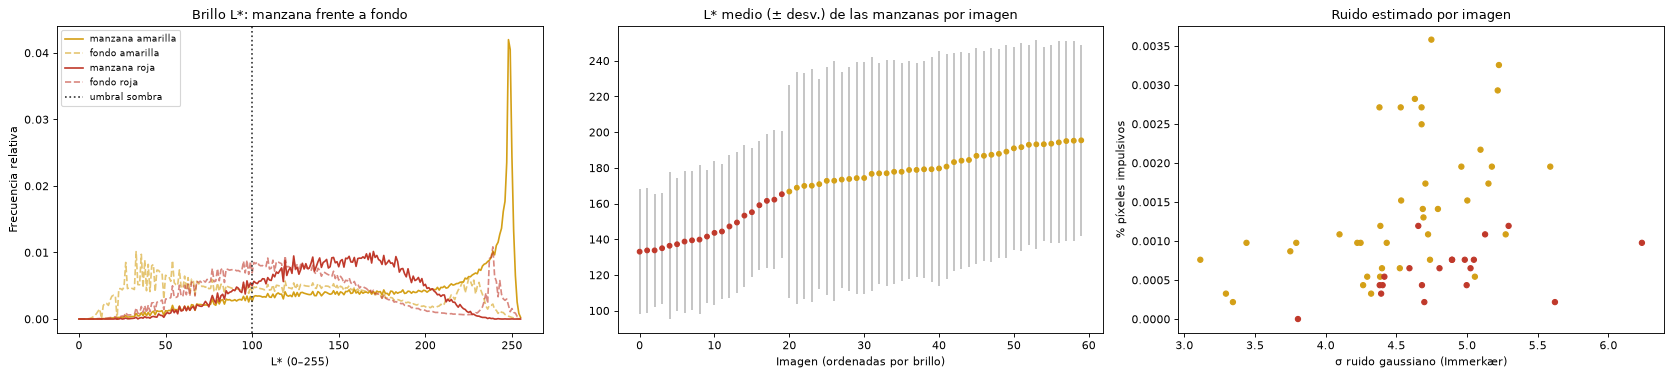

In [ ]:
figura, ejes = plt.subplots(1, 3, figsize=(21, 4.8))

# Histograma de brillo L* de manzana y fondo, por variedad
for variedad in ["amarilla", "roja"]:
    histograma_manzana = np.zeros(256)
    histograma_fondo = np.zeros(256)
    for muestra in train:
        if muestra.variety == variedad:
            imagen, mascara = redimensionar(muestra)
            brillo = cv2.cvtColor(imagen, cv2.COLOR_RGB2LAB)[:, :, 0]
            histograma_manzana += np.bincount(brillo[mascara], minlength=256)
            histograma_fondo += np.bincount(brillo[~mascara], minlength=256)
    ejes[0].plot(histograma_manzana / histograma_manzana.sum(), color=COLORES[variedad], label=f"manzana {variedad}")
    ejes[0].plot(histograma_fondo / histograma_fondo.sum(), "--", color=COLORES[variedad], alpha=0.6, label=f"fondo {variedad}")
ejes[0].axvline(100, color="#333", linestyle=":", label="umbral sombra")
ejes[0].set_title("Brillo L*: manzana frente a fondo")
ejes[0].set_xlabel("L* (0–255)")
ejes[0].set_ylabel("Frecuencia relativa")
ejes[0].legend(fontsize=8)

# Brillo medio de las manzanas de cada imagen, ordenadas de más oscura a más clara
pares = []
for fila in calidad:
    pares.append((fila["L_manzana"], fila["L_std_manzana"], fila["variedad"]))
pares.sort()
medias = []
desviaciones = []
colores_puntos = []
for media, desviacion, variedad in pares:
    medias.append(media)
    desviaciones.append(desviacion)
    colores_puntos.append(COLORES[variedad])
ejes[1].errorbar(range(len(medias)), medias, yerr=desviaciones, fmt="none", ecolor="#bbb")
ejes[1].scatter(range(len(medias)), medias, c=colores_puntos, s=18, zorder=3)
ejes[1].set_title("L* medio (± desv.) de las manzanas por imagen")
ejes[1].set_xlabel("Imagen (ordenadas por brillo)")

# Ruido estimado
sigmas = []
impulsivos = []
colores_puntos = []
for fila in calidad:
    sigmas.append(fila["sigma_ruido"])
    impulsivos.append(100 * fila["impulsivo"])
    colores_puntos.append(COLORES[fila["variedad"]])
ejes[2].scatter(sigmas, impulsivos, c=colores_puntos, s=22)
ejes[2].set_title("Ruido estimado por imagen")
ejes[2].set_xlabel("σ ruido gaussiano (Immerkær)")
ejes[2].set_ylabel("% píxeles impulsivos")

figura.tight_layout()
guardar_figura(figura, "iluminacion_calidad.png")

El histograma de L\* de las manzanas amarillas tiene un pico junto a 255. Comprobamos si esto significa que el color se pierde (píxeles
blancos) mirando el color de los píxeles sobreexpuestos:

In [21]:
pixeles = []
for muestra in train:
    if muestra.variety == "amarilla":
        pixeles.append(muestra.image[muestra.mask])
pixeles = np.concatenate(pixeles)

sobreexpuestos = pixeles.max(axis=1) >= 250
blancos = pixeles.min(axis=1) >= 250
rgb_medio = pixeles[sobreexpuestos].mean(axis=0)

print(f"Píxeles de manzana amarilla sobreexpuestos: {100 * sobreexpuestos.mean():.1f} %")
print(f"Píxeles blancos de verdad (R, G y B ≥ 250): {100 * blancos.mean():.2f} %")
print(f"RGB medio de los sobreexpuestos: R={rgb_medio[0]:.0f} G={rgb_medio[1]:.0f} B={rgb_medio[2]:.0f}")
for indice, canal in enumerate(["R", "G", "B"]):
    recortado = pixeles[sobreexpuestos, indice] >= 250
    print(f"  {canal} recortado en el {100 * recortado.mean():.0f} % de ellos")

Píxeles de manzana amarilla sobreexpuestos: 25.5 %
Píxeles blancos de verdad (R, G y B ≥ 250): 0.07 %
RGB medio de los sobreexpuestos: R=253 G=252 B=109
  R recortado en el 91 % de ellos
  G recortado en el 78 % de ellos
  B recortado en el 1 % de ellos


**Interpretación y decisiones.**

- **Iluminación muy variable**: el L\* medio de las manzanas cambia mucho entre imágenes y, dentro de cada una, la
  desviación es grande (sol frente a sombra; un 13–20 % de los píxeles de manzana están en sombra). Justifica
  **CLAHE** sobre L\* (o V), que ecualiza el contraste por regiones sin tocar el color.
- **Sobreexposición en las amarillas**: alrededor de una cuarta parte de sus píxeles de manzana tienen R y G recortados
  a 255, pero B sigue bajo (≈ 110): siguen siendo **amarillo intenso, no blanco**. El brillo deja de ser fiable ahí (ni
  gamma ni CLAHE recuperan lo recortado), pero **los canales cromáticos siguen funcionando**: otra razón para segmentar
  por color y no por brillo.
- **Brillos especulares**: poco frecuentes en general, pero en algunas imágenes amarillas llegan al ~10 % de la manzana
  → huecos blancos dentro de las manzanas → **mediana** y **cierre morfológico**.
- **Ruido bajo**: σ gaussiano de 3 a 6 niveles de gris y prácticamente **ningún píxel de sal y pimienta** natural. El
  suavizado (gaussiano, bilateral) servirá más para homogeneizar la textura de las hojas que para quitar ruido de sensor,
  y el filtro de mediana frente a impulsos se evaluará con **ruido sintético** (experimento de robustez del preprocesado,
  con `src/preprocesado/ruido.py`).

## 10. ¿Son completas las anotaciones?

El enunciado pide identificar las manzanas del **árbol situado frente al robot**. En las imágenes se ven también frutos
de las filas del fondo. Comprobamos si están anotados: umbralizamos el mejor gris de manzana con su umbral de máximo F1
y miramos las regiones del tamaño de una manzana que caen **fuera** de la máscara. Se muestra la imagen roja de
validación con más píxeles detectados fuera de la máscara (el peor caso, a propósito).

img_083: 35 regiones del tamaño de una manzana detectadas por color que no tocan ninguna anotación (umbral 159 sobre '(Cr + 255 − Cb) / 2').


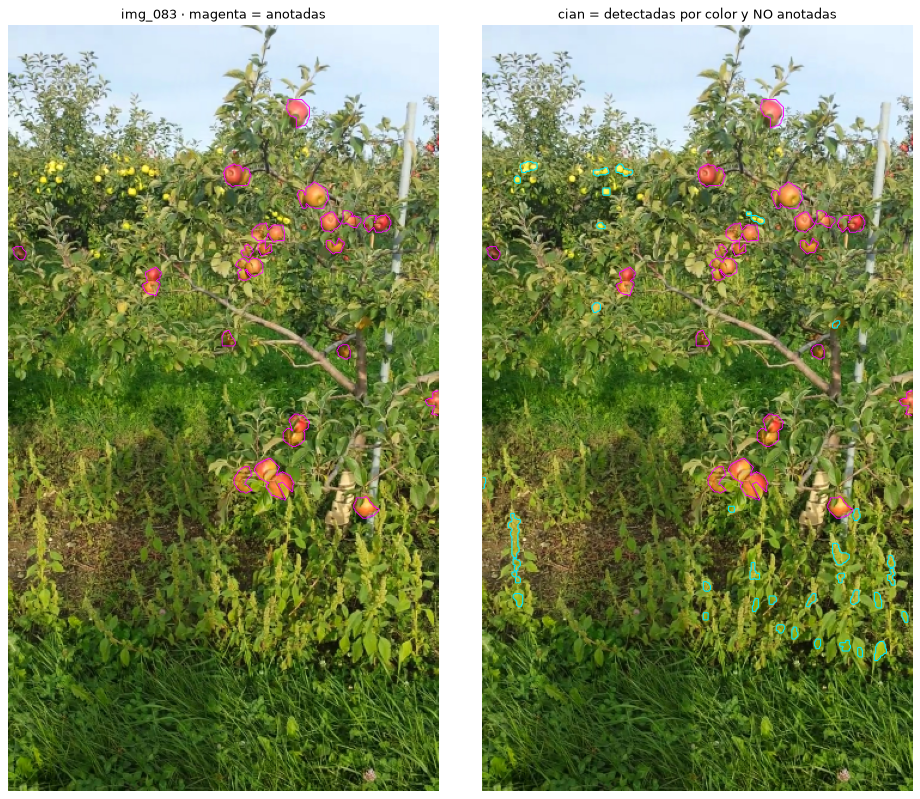

In [22]:
mejor_candidato = orden[0]
funcion = candidatos[mejor_candidato]
umbral = resultados[(mejor_candidato, "todas")]["best_f1_threshold"]

# Elegir la imagen roja de validación con más píxeles detectados fuera de la máscara
peor_muestra = None
mas_pixeles_fuera = -1
for muestra in validacion:
    if muestra.variety == "roja":
        imagen, mascara = redimensionar(muestra)
        detectado = funcion(imagen) >= umbral
        pixeles_fuera = np.sum(detectado & ~mascara)
        if pixeles_fuera > mas_pixeles_fuera:
            mas_pixeles_fuera = pixeles_fuera
            peor_muestra = muestra

imagen, mascara = redimensionar(peor_muestra)
detectado = (funcion(imagen) >= umbral).astype(np.uint8)
detectado = cv2.morphologyEx(detectado, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

# Quedarse con las regiones del tamaño de una manzana que no tocan ninguna anotación
numero_regiones, etiquetas, estadisticas, _ = cv2.connectedComponentsWithStats(detectado, connectivity=8)
no_anotadas = np.zeros(mascara.shape, dtype=bool)
cuenta_no_anotadas = 0
for etiqueta in range(1, numero_regiones):
    region = etiquetas == etiqueta
    area = estadisticas[etiqueta, cv2.CC_STAT_AREA]
    toca_anotacion = np.any(region & mascara)
    if area >= area_minima and not toca_anotacion:
        no_anotadas = no_anotadas | region
        cuenta_no_anotadas += 1

print(f"{peor_muestra.image_id}: {cuenta_no_anotadas} regiones del tamaño de una manzana detectadas por color que "
      f"no tocan ninguna anotación (umbral {umbral} sobre '{mejor_candidato}').")

figura, ejes = plt.subplots(1, 2, figsize=(12, 10))
ejes[0].imshow(imagen)
ejes[0].contour(mascara, levels=[0.5], colors="#ff00ff", linewidths=0.8)
ejes[0].set_title(f"{peor_muestra.image_id} · magenta = anotadas")
ejes[1].imshow(imagen)
ejes[1].contour(mascara, levels=[0.5], colors="#ff00ff", linewidths=0.8)
ejes[1].contour(no_anotadas, levels=[0.5], colors="#00e5ff", linewidths=1.0)
ejes[1].set_title("cian = detectadas por color y NO anotadas")
ejes[0].axis("off")
ejes[1].axis("off")
figura.tight_layout()
guardar_figura(figura, "anotaciones_incompletas.png")

En la parte superior izquierda se ven decenas de **manzanas amarillas de la fila del fondo sin
anotar**; unas cuantas superan el umbral y el área mínima (contornos cian de arriba). La mayoría de las regiones cian, en
cambio, son **hierbas y tallos iluminados** de la parte baja. Consecuencias:

- Las anotaciones **solo cubren el árbol de delante**. Lo que un método de color detecte en los árboles del fondo contará
  como **falso positivo** aunque sea una manzana: la precisión medida será algo más baja que la real, sobre todo en las
  imágenes rojas, y explica en parte el AP tan bajo de los canales amarillos en ellas (sección 6).
- El **filtro de área mínima** descarta la mayoría de esas manzanas lejanas (se ven más pequeñas), y debe explicarse en
  la discusión de la memoria como una limitación de las anotaciones, no del modelo.
- Las hierbas iluminadas tienen el mismo color que una manzana pero **forma alargada e irregular**: confirma que hace falta
  el filtro por **circularidad/solidez** o la información de **textura** de la sección 7.

## 11. Conclusiones: qué decide este EDA

| Hallazgo (sección) | Decisión | Fase |
|---|---|---|
| 66 imágenes amarillas (`img_000`–`065`) y 34 rojas (`066`–`099`) (2) | Split estratificado 60/20/20 y análisis por variedad | Datos |
| ~4 % de píxeles de manzana; todo fondo da accuracy 0,96 con F1 = 0 (4) | Métricas F1/Dice, IoU, MCC, PR-AUC; muestreo balanceado | Métricas, modelos |
| El gris estándar separa mal (AUC 0,65 en rojas) (5) | P0 (sin preprocesado) será la línea base mala, como predice el profesor | Experimentos |
| Cada variedad tiene su canal: Cb/b\* (amarillas), Cr/a\*/matiz (rojas) (5) | Convertir a YCrCb/Lab; matiz como distancia circular al rojo | Preprocesado (P5) |
| (Cr + 255 − Cb)/2 multiplica por ~5 el AP del gris estándar (6) | "Gris de manzana" principal; retroproyección como alternativa aprendida | Preprocesado (P6) |
| Las medidas simples de rugosidad separan poco; la distribución de códigos LBP sí (AUC ≈ 0,8 frente al fondo que el color confunde, elimina ~la mitad de ese fondo) y es poco redundante con el color (7) | Color + LBP local (ventana 9–11 px) + desviación y Sobel con ventanas de 3–5 px como características; ventanas como hiperparámetros | Modelos (M5–M7) |
| Ventanas mayores que una manzana miden su borde, no su piel (7) | Rangos de ventana acotados por el tamaño de la manzana | Modelos, Optuna |
| Manzanas pequeñas (r ≈ 6 px a escala 0,5) y casi redondas (8) | Área mínima, apertura ≤ 3×3, filtro de circularidad, Hough con radios 3–17 px | Postprocesado, M8 |
| ~17 % de manzanas fusionadas u ocluidas (8) | Watershed para separar y contar | Postprocesado, métricas por objeto |
| Muchas más manzanas amarillas que rojas (8) | Muestreo por variedad en modelos supervisados | Modelos |
| Iluminación sol/sombra muy variable (9) | CLAHE sobre L\* | Preprocesado (P4) |
| Sobreexposición en amarillas, pero el color se conserva (9) | Segmentar por color, no por brillo | Preprocesado |
| Brillos especulares puntuales (9) | Mediana + cierre morfológico | Preprocesado, postprocesado |
| Ruido bajo y sin sal y pimienta natural (9) | Evaluar filtros de ruido con ruido sintético | Experimento de robustez |
| Manzanas del fondo no anotadas; hierbas iluminadas con color de manzana (10) | Filtro de área y de forma; explicarlo en la discusión | Postprocesado, memoria |

Todos los CSV y figuras se guardan en `resultados/eda/`.